<a href="https://colab.research.google.com/github/navya1870/Statistics-Tutorial/blob/main/statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

Percentiles,IQR and Handling Outliers

In [ ]:
arr = np.array([1,2,3,4,4,5,6,7,10,12,13,15,17,18,21,22,23,25,105])
arr

array([  1,   2,   3,   4,   4,   5,   6,   7,  10,  12,  13,  15,  17,
        18,  21,  22,  23,  25, 105])

In [ ]:
Q1 = np.percentile(arr, 25)
Q3 = np.percentile(arr, 75)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 4.5
Q3: 19.5
IQR: 15.0


In [ ]:
UF = Q3 + 1.5 * IQR
LF = Q1 - 1.5 * IQR
print("UF:", UF)
print("LF:", LF)

UF: 42.0
LF: -18.0


method 1 to get array with removed outliers by boolean indexing

In [ ]:
bool_index = (arr <= UF) & (arr >=LF)
bool_index

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False])

In [ ]:
arr2 = arr[bool_index]
arr2

array([ 1,  2,  3,  4,  4,  5,  6,  7, 10, 12, 13, 15, 17, 18, 21, 22, 23,
       25])

Five Number Summary

In [ ]:
min = np.percentile(arr2,0)
q1 = np.percentile(arr2,25)
q2 = np.percentile(arr2,50)
q3 = np.percentile(arr2,75)
max = np.percentile(arr2,100)
print("min:",min)
print("q1:",q1)
print("q2:",q2)
print("q3:",q3)
print("max:",max)

min: 1.0
q1: 4.25
q2: 11.0
q3: 17.75
max: 25.0


method 2 of getting outlier free array

In [ ]:
l = []
for i in arr:
  if (i >= LF) & (i <= UF):
    l.append(i)
arr3 = np.array(l)
arr3

array([ 1,  2,  3,  4,  4,  5,  6,  7, 10, 12, 13, 15, 17, 18, 21, 22, 23,
       25])

Boxplot

<Axes: >

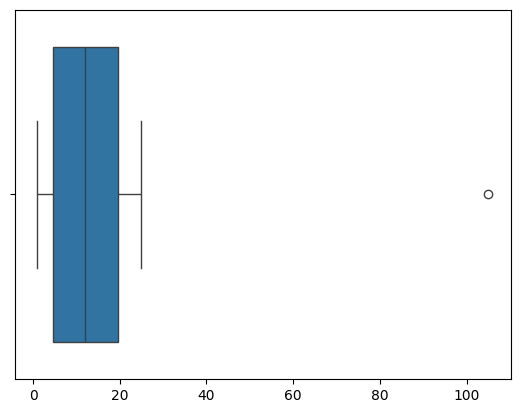

In [ ]:
import seaborn as sns
sns.boxplot(x = arr)

<Axes: >

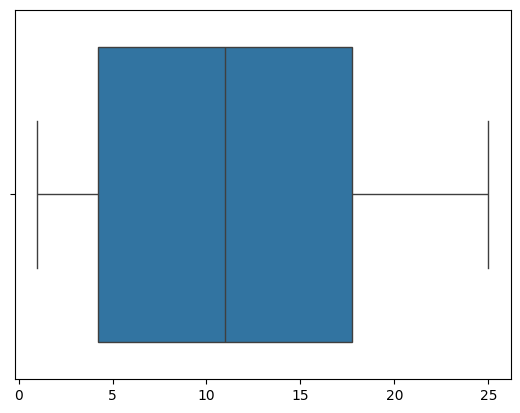

In [ ]:
sns.boxplot(x = arr2)

<Axes: >

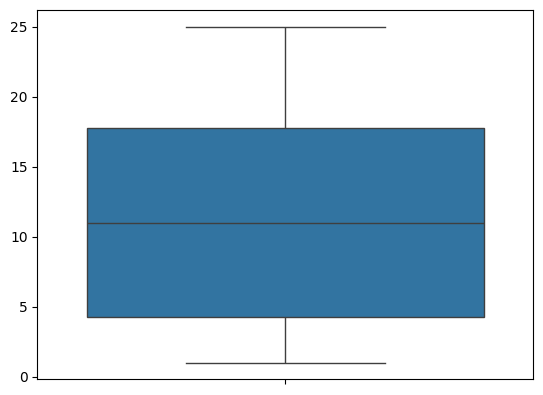

In [ ]:
sns.boxplot(arr3)

Z-Test

In [ ]:
from scipy.stats import norm

In [2]:
#given info
#yha pr sample sixe 30 se jyda ni h still z test lga rhe h this is wrong but this is just for example
sample = [172,174,168,169,171,173,175,170,169,172]
population_mean = 170
population_std = 3

sample_mean = np.mean(sample)
n = len(sample)
#yha pr z is less than 1.96 which is going to be the critical value and we will accept the null hypothesis but we will solve it by p value

In [ ]:
z_score = (sample_mean - population_mean)/(population_std/np.sqrt(n))
z_score

np.float64(1.3703203194063098)

In [ ]:
p_value = 2 * (1 - norm.cdf(abs(z_score)))
p_value

np.float64(0.17058693287143756)

In [ ]:
alpha = 0.05
if p_value>alpha:
  print("accept null hypothesis")
else:
  print("reject null hypothesis")

accept null hypothesis


In [ ]:
from scipy import stats

T test

In [ ]:
sample = [172,174,168,169,171,173,175,170,169,172]
sample_mean = np.mean(sample)
sample_std = np.std(sample,ddof = 1) #ddof = degree of freedom , t test me df 1 hi lete h
n = len(sample)
population_mean = 170 # ye khud se le liye bcs vese to ye given hota h

In [ ]:
t_stats = (sample_mean - population_mean)/(sample_std/np.sqrt(n))
t_stats
#critical value would be 2.262 if alpha = 0.05 therefore we would accept null hypothesis by critical value

np.float64(1.7782469350914734)

In [ ]:
p_value = 2* (1 - stats.t.cdf(abs(t_stats),df = n-1))
p_value

np.float64(0.10907771593031335)

In [ ]:
alpha = 0.05
if p_value>alpha:
  print("accept null hypothesis")
else:
  print("reject null hypothesis")

accept null hypothesis


Two sample test by p value

In [ ]:
from scipy import stats

In [ ]:
groupA = [88,85,90,92,87,85,89,91,86,88]
groupB = [82,84,80,83,81,79,78,85,84,83]
sample_mean_A = np.mean(groupA)
sample_mean_B = np.mean(groupB)
sample_std_A = np.std(groupA,ddof = 1)
sample_std_B = np.std(groupB,ddof = 1)
n_A = len(groupA)
n_B = len(groupB)
#ab yha se t_stats ki value nikalo fir df nikalo fir p value nikalo aur fir comare with alpha

In [ ]:
t_stats,p_value = stats.ttest_ind(groupA,groupB,equal_var=False)
t_stats,p_value

(np.float64(5.829604009507161), np.float64(1.610475598965881e-05))

In [ ]:
alpha = 0.05
if p_value<alpha:
  print("reject null hypothesis")
else:
  print("accept null hypothesis")

reject null hypothesis


Chi square test by p value

In [ ]:
import seaborn as sns
from scipy.stats import chi2_contingency
import pandas as pd

In [ ]:
#ye titatnic already sns me hi dataframe h built in df h ye
df = sns.load_dataset("titanic")
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [ ]:
contingency_table = pd.crosstab(df["sex"],(df["survived"]))
contingency_table

survived,0,1
sex,,
female,81,233
male,468,109


In [ ]:
chi2,p_value,dof,expected = chi2_contingency(contingency_table)
chi2,p_value,dof,expected

(np.float64(260.71702016732104),
 np.float64(1.1973570627755645e-58),
 1,
 array([[193.47474747, 120.52525253],
        [355.52525253, 221.47474747]]))

In [ ]:
alpha = 0.05
if p_value>alpha:
  print("accept null hypothesis")
else:
  print("reject null hypothesis and there is a relationship between survived and sex")

reject null hypothesis and there is a relationship between survived and sex


ANOVA test

In [ ]:
import seaborn as sns
import pandas as pd
from scipy.stats import f_oneway   #annova test is also called f test

In [ ]:
df = sns.load_dataset("titanic")
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [ ]:
df["pclass"].unique()

array([3, 1, 2])

data cleaning is necessary isme null values thi usseclass me aur f stats me error ara tha

In [ ]:
df = df[['age','pclass']].dropna()
df

,age,pclass
0,22.0,3
1,38.0,1
2,26.0,3
3,35.0,1
4,35.0,3
...,...,...
885,39.0,3
886,27.0,2
887,19.0,1
889,26.0,1


In [ ]:
class1 = df[df["pclass"]==1]["age"]
class2 = df[df["pclass"]==2]["age"]
class3 = df[df["pclass"]==3]["age"]
print(class1)

1      38.0
3      35.0
6      54.0
11     58.0
23     28.0
       ... 
871    47.0
872    33.0
879    56.0
887    19.0
889    26.0
Name: age, Length: 186, dtype: float64


In [ ]:
f_stats,p_value = f_oneway(class1,class2,class3)
f_stats,p_value

(np.float64(57.44348434067624), np.float64(7.487984171959213e-24))

In [ ]:
alpha = 0.05
if p_value>alpha:
  print("accept null hypothesis")
else:
  print("reject null hypothesis")

reject null hypothesis
